# 🎬 Sentiment Analysis on IMDB Reviews (TF-IDF Models vs Fine-Tuned DistilBERT)

**Problem:** 50,000 IMDB movie reviews ko **positive / negative** me classify karna.

**Is notebook me kya hota hai:**
1. Data quality (duplicates, HTML tags), EDA, aur **leak-free split** (train / validation / test)
2. **Classical models** (TF-IDF 1-2 gram): Naive Bayes, Linear SVM, Logistic Regression, validation pe tuning
3. **DistilBERT fine-tuning** (custom PyTorch loop, mixed precision), GPU chahiye
4. **Honest comparison:** accuracy + **95% bootstrap CI**, macro-F1, ROC-AUC, log-loss, calibration, **speed aur model size**
5. **Explainability:** Logistic Regression ke word contributions (har review ke liye)
6. **Error analysis:** confident galat predictions, review length ka effect, models ka disagreement, ensemble
7. Models aur results save + ek cell me sab outputs ka zip

**Dataset:** https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

**Kaggle setup:**
- Add Input, dataset add karo (path auto-detect hota hai)
- **DistilBERT part ke liye:** Settings, Accelerator, **GPU T4 x2** aur Settings, **Internet ON** (pretrained weights download hote hain)
- GPU/Internet na ho toh bhi notebook chalega: transformer section skip ho jata hai aur baaki sab chalta hai
- Run time: ~10 min (sirf classical), ~25 min (GPU ke saath)

## 1. Setup & Config

In [1]:
import os, re, json, time, html, random, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, log_loss, roc_curve,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# ------------------------------ CONFIG ------------------------------
SEED = 42
VAL_SIZE, TEST_SIZE = 5000, 5000          # baaki sab train
RUN_TRANSFORMER = True                    # False karo toh sirf classical models chalenge
MODEL_NAME = "distilbert-base-uncased"
MAX_LEN, BATCH_TRAIN, BATCH_EVAL = 256, 32, 128
EPOCHS, LEARNING_RATE = 2, 2e-5
TRAIN_SUBSET = None                       # e.g. 10000 se transformer training jaldi hoti hai (None = poora train)
ALLOW_CPU = False                         # True: GPU ke bina bhi chalega (bahut slow, TRAIN_SUBSET chhota rakho)
# --------------------------------------------------------------------

random.seed(SEED); np.random.seed(SEED)
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
SEARCH_ROOTS = [r for r in ["/kaggle/input", "."] if os.path.exists(r)]
print("Output dir:", OUT_DIR)

Output dir: /kaggle/working


## 2. Load Data (path auto-detect)

In [2]:
def find_reviews_csv():
    for root in SEARCH_ROOTS:
        for dirpath, _, files in os.walk(root):
            for f in files:
                if f.lower().endswith(".csv") and not f.lower().startswith(("demo_", "results", "per_", "custom_")):
                    p = os.path.join(dirpath, f)
                    try:
                        cols = [c.lower() for c in pd.read_csv(p, nrows=0).columns]
                    except Exception:
                        continue
                    if {"review", "sentiment"} <= set(cols):
                        return p
    raise FileNotFoundError("IMDB CSV (review, sentiment) nahi mila. Kaggle me 'Add Input' se dataset add karo.")

path = find_reviews_csv()
print("File:", path)
raw = pd.read_csv(path)
raw.columns = [c.lower() for c in raw.columns]
print("Shape:", raw.shape)
raw.head(3)

File: /kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv
Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


## 3. Data Quality Checks & Cleaning

In [3]:
print("Missing values :", int(raw[["review", "sentiment"]].isna().sum().sum()))
n_dup = int(raw.duplicated(subset="review").sum())
print("Duplicate reviews:", n_dup)
print("Label values:", raw["sentiment"].value_counts().to_dict())
print("Reviews with HTML tags (<br />...):", int(raw["review"].str.contains(r"<[^>]+>", regex=True).sum()))

def clean_text(t):
    t = html.unescape(str(t))
    t = re.sub(r"<[^>]+>", " ", t)          # <br /> jaise HTML tags hatao
    t = re.sub(r"\s+", " ", t).strip()
    return t

df = raw.dropna(subset=["review", "sentiment"]).drop_duplicates(subset="review").reset_index(drop=True)
df["label"] = (df["sentiment"].str.lower() == "positive").astype(int)
df["clean"] = df["review"].map(clean_text)
df["words"] = df["clean"].str.split().str.len()

print(f"\nAfter dedup: {len(df):,} reviews | positive {int(df.label.sum()):,} | negative {int((1 - df.label).sum()):,}")
print("Words per review: mean %.0f | median %.0f | p95 %.0f | max %d" % (
    df.words.mean(), df.words.median(), df.words.quantile(0.95), df.words.max()))
print("\nExample (cleaned):", textwrap.shorten(df.loc[0, "clean"], 260))

Missing values : 0
Duplicate reviews: 418
Label values: {'positive': 25000, 'negative': 25000}
Reviews with HTML tags (<br />...): 29202

After dedup: 49,582 reviews | positive 24,884 | negative 24,698
Words per review: mean 229 | median 172 | p95 585 | max 2459

Example (cleaned): One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which [...]


## 4. Train / Validation / Test Split

Stratified split (seed fixed). Models **train** pe fit hote hain, hyperparameters **validation** pe chune jate hain,
aur **test sirf aakhir me ek baar** use hota hai.

In [4]:
train_df, tmp_df = train_test_split(df, test_size=VAL_SIZE + TEST_SIZE, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=TEST_SIZE, stratify=tmp_df["label"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

y_tr, y_va, y_te = train_df["label"].values, val_df["label"].values, test_df["label"].values
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):>6,} reviews | positive {100 * d.label.mean():.1f}%")

train: 39,582 reviews | positive 50.2%
val  :  5,000 reviews | positive 50.2%
test :  5,000 reviews | positive 50.2%


## 5. Exploratory Data Analysis (train set)

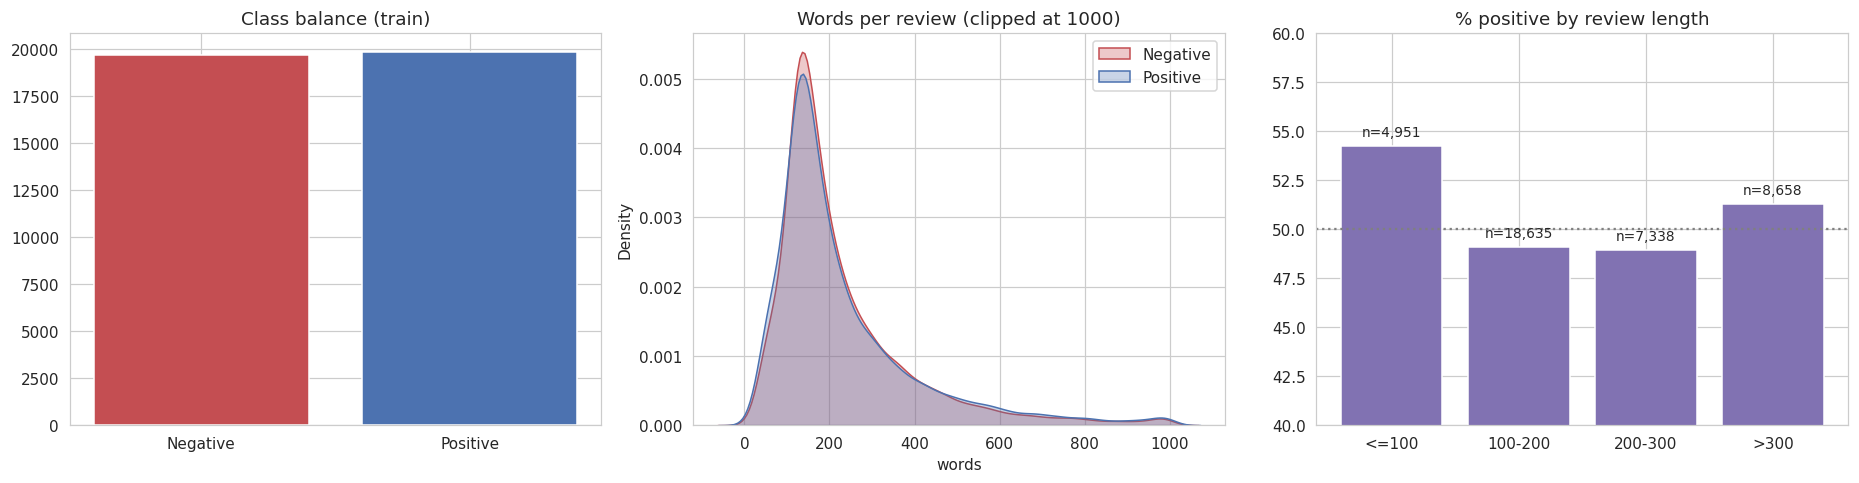

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].bar(["Negative", "Positive"], [int((1 - y_tr).sum()), int(y_tr.sum())], color=["#C44E52", "#4C72B0"])
ax[0].set_title("Class balance (train)")

for lab, c, nm in [(0, "#C44E52", "Negative"), (1, "#4C72B0", "Positive")]:
    sns.kdeplot(train_df.loc[train_df.label == lab, "words"].clip(upper=1000), ax=ax[1], color=c, fill=True, alpha=0.3, label=nm)
ax[1].set_title("Words per review (clipped at 1000)"); ax[1].set_xlabel("words"); ax[1].legend()

by_len = train_df.assign(bucket=pd.cut(train_df.words, [0, 100, 200, 300, 100000], labels=["<=100", "100-200", "200-300", ">300"]))
tbl = by_len.groupby("bucket", observed=True)["label"].agg(["mean", "size"])
ax[2].bar(tbl.index.astype(str), 100 * tbl["mean"], color="#8172B2")
ax[2].axhline(50, color="gray", ls=":")
for i, (m, n) in enumerate(zip(tbl["mean"], tbl["size"])):
    ax[2].text(i, 100 * m + 0.5, f"n={n:,}", ha="center", fontsize=9)
ax[2].set_title("% positive by review length"); ax[2].set_ylim(40, 60)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "eda_overview.png"), dpi=150); plt.show()

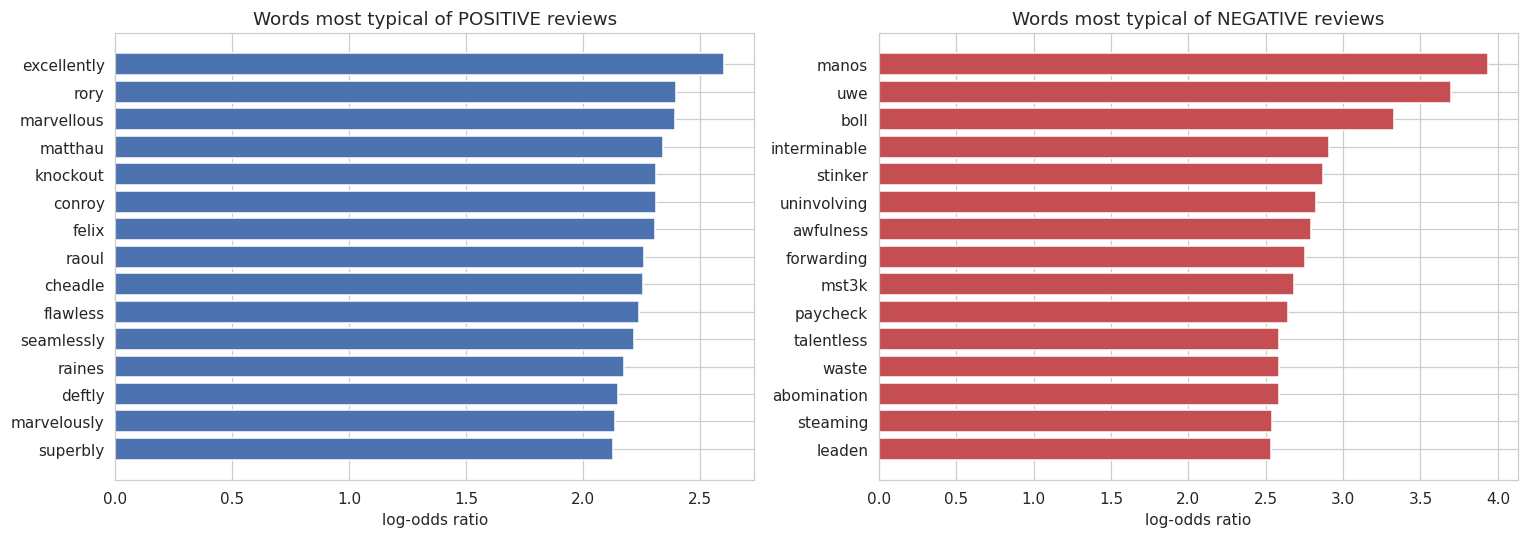

In [6]:
# Sabse discriminative words (smoothed log-odds, sirf train data se)
cv = CountVectorizer(min_df=30, stop_words="english", binary=True)
Xc = cv.fit_transform(train_df["clean"])
pos_c = np.asarray(Xc[y_tr == 1].sum(axis=0)).ravel() + 1
neg_c = np.asarray(Xc[y_tr == 0].sum(axis=0)).ravel() + 1
logodds = np.log(pos_c / pos_c.sum()) - np.log(neg_c / neg_c.sum())
vocab = np.array(cv.get_feature_names_out())
top_p, top_n = np.argsort(-logodds)[:15], np.argsort(logodds)[:15]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(vocab[top_p][::-1], logodds[top_p][::-1], color="#4C72B0"); ax[0].set_title("Words most typical of POSITIVE reviews")
ax[1].barh(vocab[top_n][::-1], -logodds[top_n][::-1], color="#C44E52"); ax[1].set_title("Words most typical of NEGATIVE reviews")
for a in ax: a.set_xlabel("log-odds ratio")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "eda_top_words.png"), dpi=150); plt.show()

## 6. Metrics & Helpers

Accuracy ke saath **95% bootstrap confidence interval**, macro-F1, ROC-AUC aur **log-loss** (probabilities kitni achhi hain).
Test set sirf 5,000 reviews ka hai, isliye chhote accuracy gap (<1%) statistically meaningful nahi hote. CI ye dikhata hai.

In [7]:
def boot_ci(y, pred, n=1000, seed=SEED):
    rs = np.random.default_rng(seed)
    idx = rs.integers(0, len(y), (n, len(y)))
    accs = (pred[idx] == y[idx]).mean(axis=1)
    return np.percentile(accs, [2.5, 97.5])

def evaluate(y, p):
    pred = (p >= 0.5).astype(int)
    lo, hi = boot_ci(y, pred)
    return {"Accuracy": accuracy_score(y, pred), "CI low": lo, "CI high": hi,
            "Macro F1": f1_score(y, pred, average="macro"),
            "ROC-AUC": roc_auc_score(y, p), "Log-loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))}

val_proba, test_proba, timings = {}, {}, {}

## 7. Classical Models: TF-IDF (1-2 gram)

Ek hi TF-IDF vectorizer (sirf train pe fit) teen models ko feed karta hai. Har model ka hyperparameter **validation accuracy** se chuna jata hai.

In [8]:
def make_vectorizer(ngram=(1, 2)):
    return TfidfVectorizer(ngram_range=ngram, min_df=3, max_df=0.9, sublinear_tf=True, max_features=200_000,
                           token_pattern=r"(?u)\b\w[\w']*\b", dtype=np.float32)

t0 = time.time()
vec = make_vectorizer().fit(train_df["clean"])
Xtr, Xva, Xte = (vec.transform(d["clean"]) for d in (train_df, val_df, test_df))
print(f"TF-IDF: {Xtr.shape[1]:,} features | fit+transform {time.time() - t0:.0f}s")

def tune(name, make_model, grid, Xtr_=Xtr, Xva_=Xva):
    rows, best = [], None
    for g in grid:
        m = make_model(g).fit(Xtr_, y_tr)
        acc = accuracy_score(y_va, m.predict(Xva_))
        rows.append({"param": g, "val_acc": acc})
        if best is None or acc > best[0]:
            best = (acc, g, m)
    print(f"{name:22s} " + " | ".join(f"{r['param']}: {r['val_acc']:.4f}" for r in rows) + f"  -> best {best[1]}")
    return best

dummy = DummyClassifier(strategy="prior").fit(Xtr, y_tr)
val_proba["Dummy"], test_proba["Dummy"] = dummy.predict_proba(Xva)[:, 1], dummy.predict_proba(Xte)[:, 1]

_, nb_alpha, nb = tune("Naive Bayes", lambda a: MultinomialNB(alpha=a), [0.1, 0.3, 1.0])
val_proba["Naive Bayes"], test_proba["Naive Bayes"] = nb.predict_proba(Xva)[:, 1], nb.predict_proba(Xte)[:, 1]

_, svm_c, _ = tune("Linear SVM", lambda c: LinearSVC(C=c), [0.05, 0.1, 0.3, 1.0])
svm = CalibratedClassifierCV(LinearSVC(C=svm_c), method="sigmoid", cv=3).fit(Xtr, y_tr)   # probabilities ke liye
val_proba["Linear SVM"], test_proba["Linear SVM"] = svm.predict_proba(Xva)[:, 1], svm.predict_proba(Xte)[:, 1]

_, lr_c, lr = tune("Logistic Regression", lambda c: LogisticRegression(C=c, solver="liblinear", max_iter=1000), [1, 3, 10, 30])
val_proba["Logistic Regression"], test_proba["Logistic Regression"] = lr.predict_proba(Xva)[:, 1], lr.predict_proba(Xte)[:, 1]
print(f"\nBest: NB alpha={nb_alpha} | SVM C={svm_c} | LR C={lr_c}")

TF-IDF: 200,000 features | fit+transform 45s
Naive Bayes            0.1: 0.8914 | 0.3: 0.8894 | 1.0: 0.8894  -> best 0.1
Linear SVM             0.05: 0.9090 | 0.1: 0.9146 | 0.3: 0.9216 | 1.0: 0.9210  -> best 0.3
Logistic Regression    1: 0.9130 | 3: 0.9200 | 10: 0.9224 | 30: 0.9224  -> best 10

Best: NB alpha=0.1 | SVM C=0.3 | LR C=10


In [9]:
# Ablation: bigrams kitna madad karte hain? (unigram-only TF-IDF + same LR)
vec_uni = make_vectorizer((1, 1)).fit(train_df["clean"])
lr_uni = LogisticRegression(C=lr_c, solver="liblinear", max_iter=1000).fit(vec_uni.transform(train_df["clean"]), y_tr)
acc_uni = accuracy_score(y_va, lr_uni.predict(vec_uni.transform(val_df["clean"])))
acc_bi = accuracy_score(y_va, lr.predict(Xva))
print(f"Validation accuracy -> unigram only: {acc_uni:.4f} | unigram + bigram: {acc_bi:.4f} | gain {100 * (acc_bi - acc_uni):+.2f} points")

Validation accuracy -> unigram only: 0.9052 | unigram + bigram: 0.9224 | gain +1.72 points


## 8. Explainability (Logistic Regression)

Linear model me har word ka **coefficient** hota hai. Kisi review ke liye `coefficient x TF-IDF value` batata hai ki kaun sa word prediction ko kis taraf dhakel raha hai.

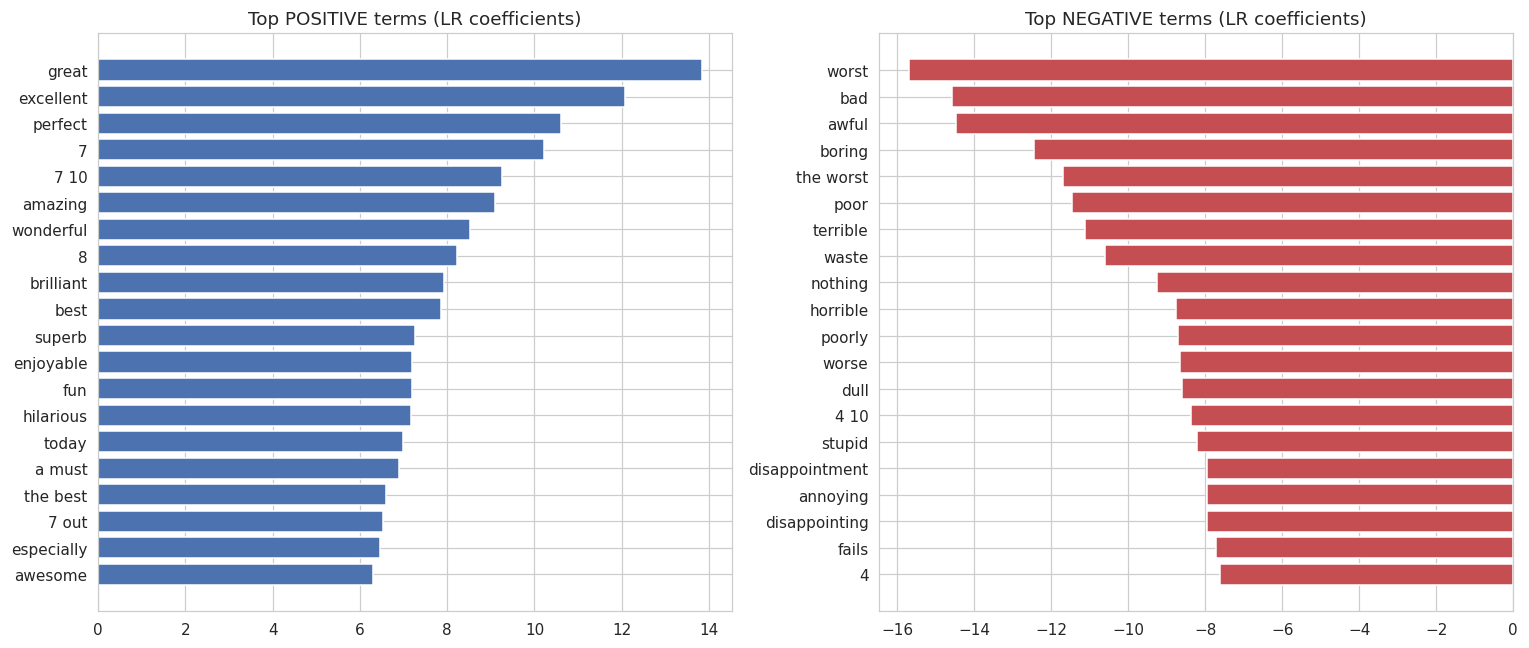

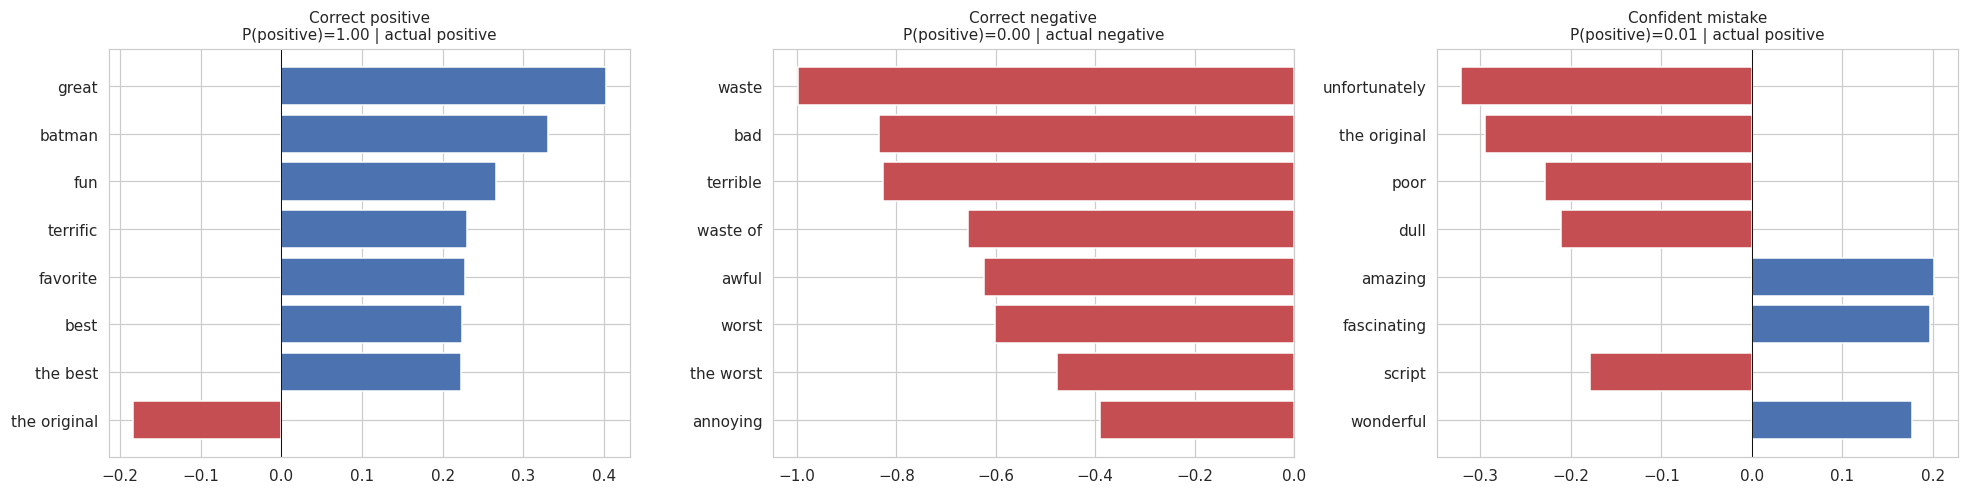

In [10]:
feat_names = np.array(vec.get_feature_names_out())
coef = lr.coef_.ravel()
top_pos, top_neg = np.argsort(-coef)[:20], np.argsort(coef)[:20]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(feat_names[top_pos][::-1], coef[top_pos][::-1], color="#4C72B0"); ax[0].set_title("Top POSITIVE terms (LR coefficients)")
ax[1].barh(feat_names[top_neg][::-1], coef[top_neg][::-1], color="#C44E52"); ax[1].set_title("Top NEGATIVE terms (LR coefficients)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "lr_top_terms.png"), dpi=150); plt.show()

def explain_lr(text, k=8):
    x = vec.transform([clean_text(text)])
    contrib = x.data * coef[x.indices]
    order = np.argsort(-np.abs(contrib))[:k]
    return pd.DataFrame({"term": feat_names[x.indices[order]], "contribution": contrib[order]})

p_lr = test_proba["Logistic Regression"]
pred_lr = (p_lr >= 0.5).astype(int)
cases = {}
ok_pos, ok_neg, bad = np.where((y_te == 1) & (pred_lr == 1))[0], np.where((y_te == 0) & (pred_lr == 0))[0], np.where(pred_lr != y_te)[0]
cases["Correct positive"] = ok_pos[np.argmax(p_lr[ok_pos])]
cases["Correct negative"] = ok_neg[np.argmin(p_lr[ok_neg])]
cases["Confident mistake"] = bad[np.argmax(np.abs(p_lr[bad] - 0.5))]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax_, (title, i) in zip(axes, cases.items()):
    e = explain_lr(test_df.loc[i, "clean"]).iloc[::-1]
    ax_.barh(e["term"], e["contribution"], color=["#4C72B0" if v > 0 else "#C44E52" for v in e["contribution"]])
    ax_.axvline(0, color="k", lw=0.6)
    ax_.set_title(f"{title}\nP(positive)={p_lr[i]:.2f} | actual {'positive' if y_te[i] else 'negative'}", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "lr_local_explanations.png"), dpi=150); plt.show()

## 9. DistilBERT Fine-Tuning (GPU)

Custom PyTorch loop (Trainer API versions ke change se bachne ke liye): dynamic padding, AdamW, linear warmup/decay, mixed precision (fp16),
gradient clipping. Har epoch ke baad **validation accuracy** dekhte hain aur **best epoch** ke weights rakhte hain.

> GPU ya Internet na ho toh ye cell error ke bajaye message dekar skip ho jata hai.

In [11]:
transformer_ok, tf_info = False, {}

if RUN_TRANSFORMER:
    try:
        import torch
        from torch.utils.data import DataLoader
        from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

        use_cuda = torch.cuda.is_available()
        if not use_cuda and not ALLOW_CPU:
            raise RuntimeError("GPU nahi mila (Settings -> Accelerator -> GPU T4 x2). CPU par chalana ho toh ALLOW_CPU=True")
        device = torch.device("cuda" if use_cuda else "cpu")
        use_amp = use_cuda                                        # fp16 sirf GPU par
        torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
        print("Device:", device)

        tok = AutoTokenizer.from_pretrained(MODEL_NAME)
        tr_sub = train_df if TRAIN_SUBSET is None else train_df.sample(TRAIN_SUBSET, random_state=SEED)

        def encode(texts):
            return tok(list(texts), truncation=True, max_length=MAX_LEN)["input_ids"]

        t0 = time.time()
        ids_tr, ids_va, ids_te = encode(tr_sub["clean"]), encode(val_df["clean"]), encode(test_df["clean"])
        print(f"Tokenised in {time.time() - t0:.0f}s | train {len(ids_tr):,} | truncated at {MAX_LEN}: "
              f"{100 * np.mean([len(x) >= MAX_LEN for x in ids_te]):.1f}% of test reviews")

        def collate(items):
            L = max(len(x) for x, _ in items)
            ids = torch.full((len(items), L), tok.pad_token_id, dtype=torch.long)
            mask = torch.zeros((len(items), L), dtype=torch.long)
            for i, (x, _) in enumerate(items):
                ids[i, :len(x)] = torch.tensor(x)
                mask[i, :len(x)] = 1
            return ids, mask, torch.tensor([y for _, y in items], dtype=torch.long)

        g = torch.Generator().manual_seed(SEED)
        train_loader = DataLoader(list(zip(ids_tr, tr_sub["label"].tolist())), batch_size=BATCH_TRAIN,
                                  shuffle=True, collate_fn=collate, generator=g)

        @torch.no_grad()
        def predict_pos(model_, ids_list, bs=BATCH_EVAL):
            model_.eval()
            order = np.argsort([len(x) for x in ids_list])          # length ke hisaab se sort: padding kam, speed zyada
            out = np.zeros(len(ids_list), dtype=np.float32)
            for s in range(0, len(order), bs):
                idx = order[s:s + bs]
                ids, mask, _ = collate([(ids_list[i], 0) for i in idx])
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                    logits = model_(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
                out[idx] = torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()
            return out

        model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
        total_steps = EPOCHS * len(train_loader)
        sched = get_linear_schedule_with_warmup(opt, int(0.06 * total_steps), total_steps)
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
        except (AttributeError, TypeError):
            scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

        best_acc, best_state, history = -1.0, None, []
        t_train = time.time()
        for epoch in range(1, EPOCHS + 1):
            model.train()
            t_ep, losses = time.time(), []
            for step, (ids, mask, labels) in enumerate(train_loader, 1):
                ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                    loss = model(input_ids=ids, attention_mask=mask, labels=labels).loss
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
                opt.zero_grad(set_to_none=True)
                losses.append(loss.item())
                if step % 200 == 0:
                    print(f"  epoch {epoch} step {step}/{len(train_loader)} loss {np.mean(losses[-200:]):.4f}")
            p_va = predict_pos(model, ids_va)
            acc = accuracy_score(y_va, (p_va >= 0.5).astype(int))
            history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "val_acc": float(acc), "seconds": time.time() - t_ep})
            print(f"epoch {epoch}/{EPOCHS}: train loss {np.mean(losses):.4f} | val acc {acc:.4f} | {time.time() - t_ep:.0f}s")
            if acc > best_acc:
                best_acc = acc
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        model.load_state_dict(best_state)
        val_proba["DistilBERT"] = predict_pos(model, ids_va)

        if use_cuda: torch.cuda.synchronize()
        t0 = time.time()
        test_proba["DistilBERT"] = predict_pos(model, ids_te)
        if use_cuda: torch.cuda.synchronize()
        tf_infer = time.time() - t0

        n_params = sum(p.numel() for p in model.parameters())
        tf_info = {"history": history, "train_seconds": time.time() - t_train, "infer_seconds_test": tf_infer,
                   "params": n_params, "best_val_acc": float(best_acc)}
        transformer_ok = True
        print(f"\nDistilBERT ready | best val acc {best_acc:.4f} | params {n_params / 1e6:.0f}M | "
              f"test inference {len(ids_te) / tf_infer:.0f} reviews/s")
    except Exception as e:
        print(f"Transformer section skip/fail: {type(e).__name__}: {str(e)[:300]}")
        print("Baaki notebook classical models ke saath chalega.")
else:
    print("RUN_TRANSFORMER=False, transformer section skip.")

Device: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenised in 23s | train 39,582 | truncated at 256: 40.7% of test reviews


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 step 200/1237 loss 0.4886
  epoch 1 step 400/1237 loss 0.2772
  epoch 1 step 600/1237 loss 0.2685
  epoch 1 step 800/1237 loss 0.2350
  epoch 1 step 1000/1237 loss 0.2414
  epoch 1 step 1200/1237 loss 0.2225
epoch 1/2: train loss 0.2876 | val acc 0.9040 | 239s
  epoch 2 step 200/1237 loss 0.1727
  epoch 2 step 400/1237 loss 0.1637
  epoch 2 step 600/1237 loss 0.1581
  epoch 2 step 800/1237 loss 0.1537
  epoch 2 step 1000/1237 loss 0.1542
  epoch 2 step 1200/1237 loss 0.1496
epoch 2/2: train loss 0.1585 | val acc 0.9204 | 240s

DistilBERT ready | best val acc 0.9204 | params 67M | test inference 759 reviews/s


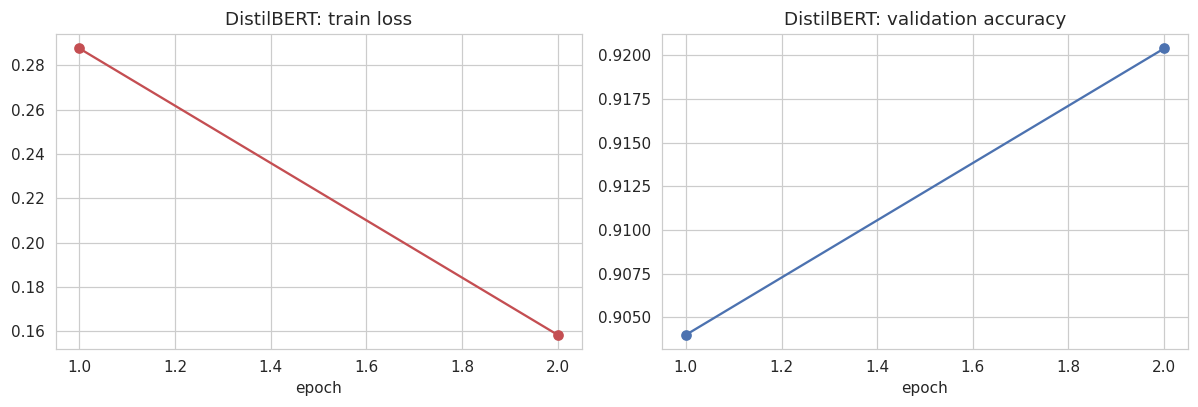

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned model to: /kaggle/working/distilbert_sentiment (bada hai, zip me nahi jayega)


In [12]:
if transformer_ok:
    h = pd.DataFrame(tf_info["history"])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(h["epoch"], h["train_loss"], marker="o", color="#C44E52"); ax[0].set_title("DistilBERT: train loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(h["epoch"], h["val_acc"], marker="o", color="#4C72B0"); ax[1].set_title("DistilBERT: validation accuracy"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "distilbert_training.png"), dpi=150); plt.show()

    save_dir = os.path.join(OUT_DIR, "distilbert_sentiment")
    model.save_pretrained(save_dir); tok.save_pretrained(save_dir)
    print("Saved fine-tuned model to:", save_dir, "(bada hai, zip me nahi jayega)")

## 10. Model Comparison on the Test Set

Test set pe **ek baar** evaluate. Selection validation se hui thi, test pe kuch tune nahi hua.

,Model,Accuracy,CI low,CI high,Macro F1,ROC-AUC,Log-loss
0,DistilBERT,0.9164,0.9086,0.9236,0.9164,0.9739,0.2335
1,Logistic Regression,0.9124,0.9042,0.9204,0.9124,0.9724,0.2171
2,Linear SVM,0.9098,0.9018,0.9176,0.9098,0.9707,0.2188
3,Naive Bayes,0.8932,0.8850,0.9020,0.8932,0.9555,0.2725
4,Dummy,0.5018,0.4878,0.5166,0.3341,0.5000,0.6931


Best on test (accuracy): DistilBERT
Top-2: DistilBERT (0.9164) vs Logistic Regression (0.9124) -> 95% CIs OVERLAP (difference statistically unclear)


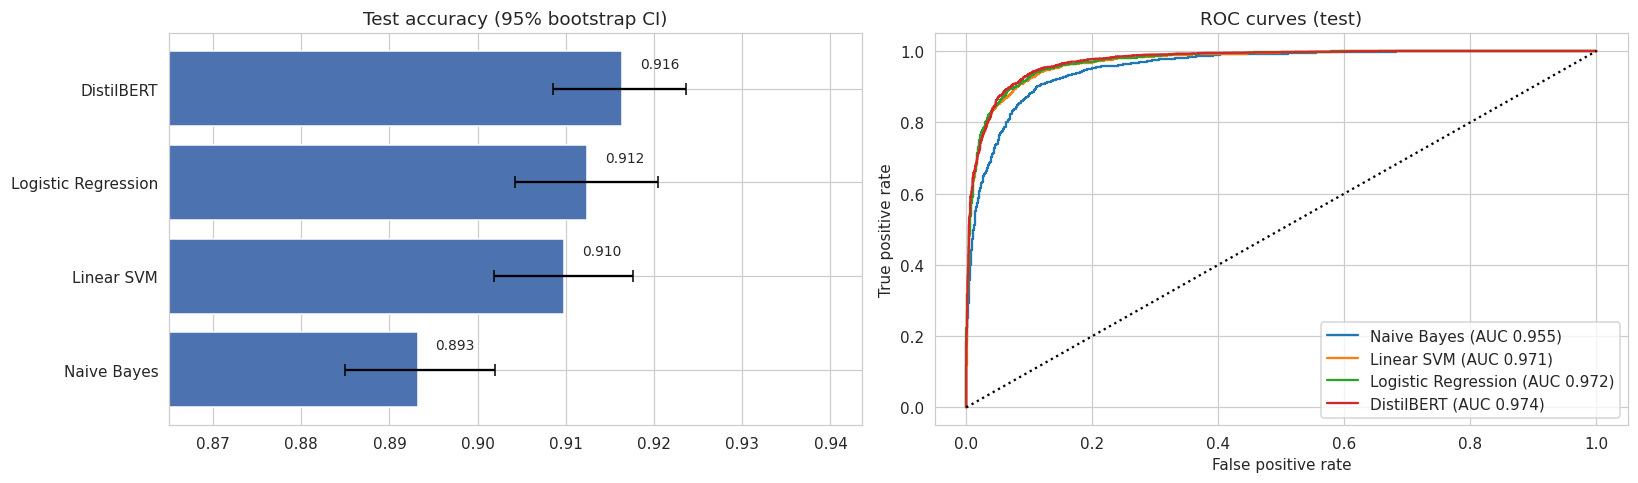

In [13]:
rows = []
for name, p in test_proba.items():
    r = {"Model": name, **evaluate(y_te, p)}
    rows.append(r)
res = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(res.round(4))

best_model = res.iloc[0]["Model"]
print("Best on test (accuracy):", best_model)
top2 = res[res["Model"] != "Dummy"].head(2)
if len(top2) == 2:
    a, b = top2.iloc[0], top2.iloc[1]
    overlap = max(a["CI low"], b["CI low"]) <= min(a["CI high"], b["CI high"])
    print(f"Top-2: {a['Model']} ({a['Accuracy']:.4f}) vs {b['Model']} ({b['Accuracy']:.4f}) -> 95% CIs "
          f"{'OVERLAP (difference statistically unclear)' if overlap else 'do not overlap'}")

plot_df = res[res["Model"] != "Dummy"].sort_values("Accuracy")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].barh(plot_df["Model"], plot_df["Accuracy"], xerr=[plot_df["Accuracy"] - plot_df["CI low"], plot_df["CI high"] - plot_df["Accuracy"]],
           color="#4C72B0", capsize=4)
for y_, v in enumerate(plot_df["Accuracy"]): ax[0].text(v + 0.002, y_ + 0.22, f"{v:.3f}", fontsize=9)
ax[0].set_xlim(max(0.8, plot_df["CI low"].min() - 0.02), min(1.0, plot_df["CI high"].max() + 0.02)); ax[0].set_title("Test accuracy (95% bootstrap CI)")

for name, p in test_proba.items():
    if name == "Dummy": continue
    fpr, tpr, _ = roc_curve(y_te, p)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curves (test)"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "model_comparison.png"), dpi=150); plt.show()

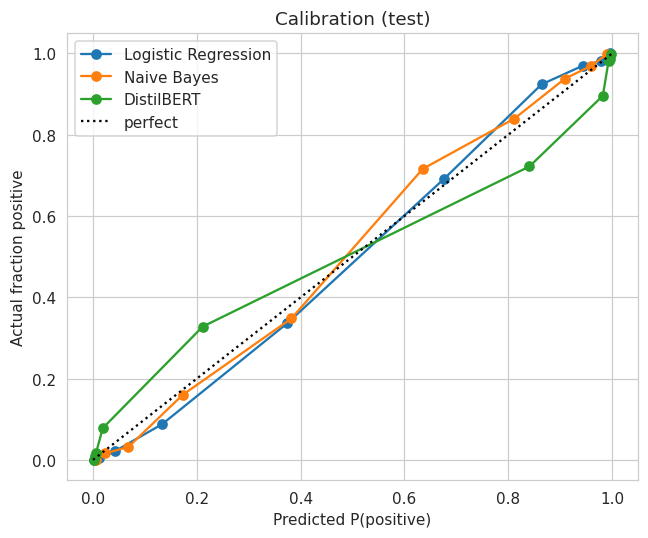

In [14]:
# Calibration: model ki probability par kitna bharosa kar sakte hain?
fig, ax = plt.subplots(figsize=(6, 5))
for name in [m for m in ["Logistic Regression", "Naive Bayes", "DistilBERT"] if m in test_proba]:
    frac, mean_p = calibration_curve(y_te, test_proba[name], n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k:", label="perfect")
ax.set_xlabel("Predicted P(positive)"); ax.set_ylabel("Actual fraction positive"); ax.set_title("Calibration (test)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "calibration.png"), dpi=150); plt.show()

In [15]:
# Speed aur size: accuracy ke saath cost bhi dekho
pipe = Pipeline([("tfidf", vec), ("clf", lr)])          # deployable pipeline: raw text -> probability
t0 = time.time(); _ = pipe.predict_proba(test_df["clean"]); lr_seconds = time.time() - t0
joblib.dump(pipe, os.path.join(OUT_DIR, "tfidf_lr.joblib"), compress=3)
lr_mb = os.path.getsize(os.path.join(OUT_DIR, "tfidf_lr.joblib")) / 1024 / 1024

speed = [{"Model": "TF-IDF + Logistic Regression (CPU)", "Reviews/sec": len(test_df) / lr_seconds, "Size (MB)": lr_mb}]
if transformer_ok:
    speed.append({"Model": f"DistilBERT ({'GPU, fp16' if use_cuda else 'CPU'})", "Reviews/sec": len(test_df) / tf_info["infer_seconds_test"],
                  "Size (MB)": tf_info["params"] * 4 / 1024 / 1024})
speed_df = pd.DataFrame(speed)
display(speed_df.round(1))

,Model,Reviews/sec,Size (MB)
0,TF-IDF + Logistic Regression (CPU),2507.8,3.8
1,"DistilBERT (GPU, fp16)",759.5,255.4


## 11. Error Analysis

Featured model: Logistic Regression | test accuracy 0.9124
              precision    recall  f1-score   support

    negative     0.9219    0.9004    0.9110      2491
    positive     0.9034    0.9243    0.9137      2509

    accuracy                         0.9124      5000
   macro avg     0.9126    0.9124    0.9124      5000
weighted avg     0.9126    0.9124    0.9124      5000



,accuracy,reviews
bucket,,
<=100,0.937,664
100-200,0.909,2330
200-300,0.909,933
>300,0.908,1073


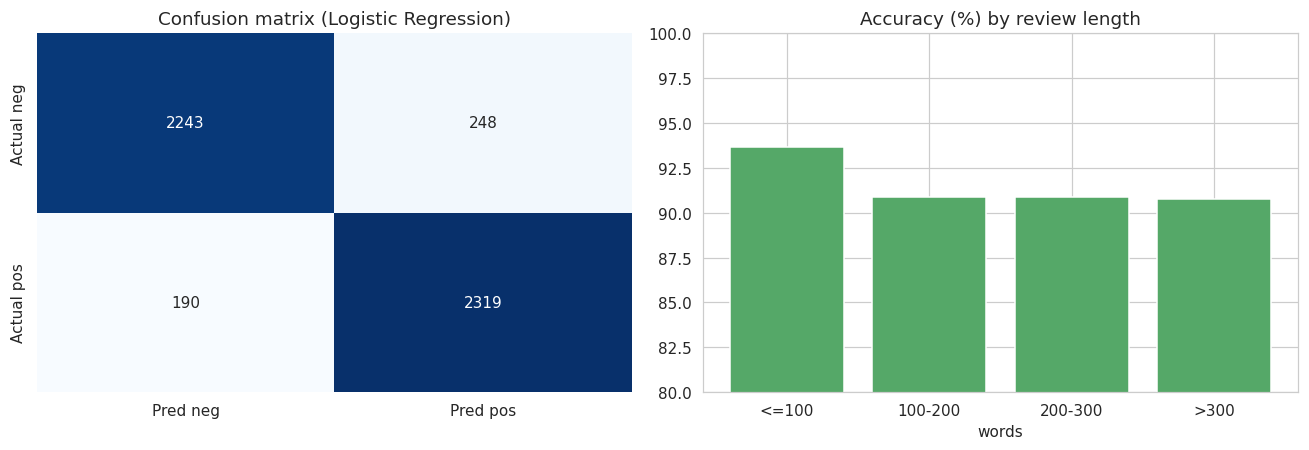

In [16]:
def val_acc(name):
    return accuracy_score(y_va, (val_proba[name] >= 0.5).astype(int))

# Featured = validation pe behtar model (test dekh ke nahi chuna)
FEATURED = "DistilBERT" if transformer_ok and val_acc("DistilBERT") >= val_acc("Logistic Regression") else "Logistic Regression"
p_f = test_proba[FEATURED]
pred_f = (p_f >= 0.5).astype(int)
print("Featured model:", FEATURED, "| test accuracy", round(accuracy_score(y_te, pred_f), 4))

cm = confusion_matrix(y_te, pred_f)
print(classification_report(y_te, pred_f, target_names=["negative", "positive"], digits=4))

# Review length ka effect
te = test_df.assign(correct=(pred_f == y_te), bucket=pd.cut(test_df.words, [0, 100, 200, 300, 100000], labels=["<=100", "100-200", "200-300", ">300"]))
by_len = te.groupby("bucket", observed=True)["correct"].agg(["mean", "size"])
display(by_len.rename(columns={"mean": "accuracy", "size": "reviews"}).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0], xticklabels=["Pred neg", "Pred pos"], yticklabels=["Actual neg", "Actual pos"])
ax[0].set_title(f"Confusion matrix ({FEATURED})")
ax[1].bar(by_len.index.astype(str), 100 * by_len["mean"], color="#55A868"); ax[1].set_ylim(80, 100)
ax[1].set_title("Accuracy (%) by review length"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "error_analysis.png"), dpi=150); plt.show()

In [17]:
# Sabse confident galat predictions
wrong = np.where(pred_f != y_te)[0]
worst = wrong[np.argsort(-np.abs(p_f[wrong] - 0.5))][:8]
print(f"Total mistakes: {len(wrong)} / {len(y_te)}\n")
for i in worst:
    print(f"[actual {'POS' if y_te[i] else 'NEG'} | model P(pos)={p_f[i]:.2f}] " + textwrap.shorten(test_df.loc[i, "clean"], 330) + "\n")

Total mistakes: 438 / 5000

[actual POS | model P(pos)=0.01] "Comanche Moon" had everything going for it. For starters, Simon Wincer's back, a man who's name is synonymous with high-quality TV westerns. Unfortunately, the problems with "Moon" are something even the most talented director couldn't solve: A poor script based on a lackluster novel. Forget historical accuracies -- as [...]

[actual NEG | model P(pos)=0.99] 'Ernest Saves Christmas' is comedian Ernest's Christmas special film. In this film, Ernest has to find a successor to Santa Claus in order for Christmas to continue. Along the way, he meets a young girl who is a thief and who ends up stealing something very important of Santa's (I won't tell you what that is; you'll just [...]

[actual NEG | model P(pos)=0.99] It is enjoyable and fast-paced. There is no way on Earth that the actor playing Mat could be eighteen. However, the main thing is that he does act eighteen very convincingly. It must be a credit to his audition tha

In [18]:
# Models kab disagree karte hain? Ensemble madad karta hai?
if transformer_ok:
    pa = (test_proba["Logistic Regression"] >= 0.5).astype(int) == y_te
    pb = (test_proba["DistilBERT"] >= 0.5).astype(int) == y_te
    agree = pd.DataFrame({"count": [int((pa & pb).sum()), int((pa & ~pb).sum()), int((~pa & pb).sum()), int((~pa & ~pb).sum())]},
                         index=["both right", "only LR right", "only DistilBERT right", "both wrong"])
    display(agree)
    ens = 0.5 * test_proba["Logistic Regression"] + 0.5 * test_proba["DistilBERT"]
    ens_acc = accuracy_score(y_te, (ens >= 0.5).astype(int))
    print(f"Ensemble (average of LR + DistilBERT) test accuracy: {ens_acc:.4f} "
          f"(DistilBERT alone {accuracy_score(y_te, (test_proba['DistilBERT'] >= 0.5).astype(int)):.4f})")
    test_proba["Ensemble (LR + DistilBERT)"] = ens
else:
    print("Transformer nahi chala, disagreement/ensemble analysis skip.")

,count
both right,4347
only LR right,215
only DistilBERT right,235
both wrong,203


Ensemble (average of LR + DistilBERT) test accuracy: 0.9314 (DistilBERT alone 0.9164)


In [19]:
# Apne sentences pe try karo (negation, sarcasm, mixed opinions)
examples = [
    "An absolute masterpiece. I was moved to tears.",
    "Worst movie I have seen in years, a complete waste of time.",
    "The movie was not good at all.",
    "I expected to hate it, but I ended up loving every minute.",
    "Great, another boring sequel. Just what the world needed.",
    "The acting was brilliant but the story made no sense.",
    "It was fine. Nothing special, nothing terrible.",
    "I would not recommend this to anyone, even for free.",
    "Not bad at all, actually quite enjoyable!",
    "The plot was predictable, yet somehow I couldn't stop watching.",
]
ex = pd.DataFrame({"review": examples})
ex["LR P(pos)"] = pipe.predict_proba(ex["review"].map(clean_text))[:, 1]
if transformer_ok:
    ex["DistilBERT P(pos)"] = predict_pos(model, encode([clean_text(t) for t in examples]))
display(ex.round(3))

,review,LR P(pos),DistilBERT P(pos)
0,An absolute masterpiece. I was moved to tears.,0.941,0.990
1,"Worst movie I have seen in years, a complete w...",0.000,0.003
2,The movie was not good at all.,0.002,0.017
3,"I expected to hate it, but I ended up loving e...",0.834,0.969
4,"Great, another boring sequel. Just what the wo...",0.151,0.013
5,The acting was brilliant but the story made no...,0.221,0.028
6,"It was fine. Nothing special, nothing terrible.",0.001,0.292
7,"I would not recommend this to anyone, even for...",0.027,0.061
8,"Not bad at all, actually quite enjoyable!",0.327,0.713
9,"The plot was predictable, yet somehow I couldn...",0.020,0.049


## 12. Save Artifacts

In [20]:
res.round(4).to_csv(os.path.join(OUT_DIR, "results_test.csv"), index=False)
speed_df.round(2).to_csv(os.path.join(OUT_DIR, "speed_size.csv"), index=False)
ex.round(4).to_csv(os.path.join(OUT_DIR, "custom_examples.csv"), index=False)
by_len.rename(columns={"mean": "accuracy", "size": "reviews"}).round(4).to_csv(os.path.join(OUT_DIR, "accuracy_by_length.csv"))

coef_df = pd.DataFrame({"term": feat_names, "coefficient": coef}).sort_values("coefficient")
pd.concat([coef_df.head(25), coef_df.tail(25)]).round(4).to_csv(os.path.join(OUT_DIR, "lr_top_terms.csv"), index=False)

# Demo reviews (app ke liye): 300 test reviews + model probabilities
demo = test_df.sample(300, random_state=SEED)[["clean", "label", "words"]].rename(columns={"clean": "text"})
demo["lr_prob"] = test_proba["Logistic Regression"][demo.index]
if transformer_ok:
    demo["distilbert_prob"] = test_proba["DistilBERT"][demo.index]
demo.round(4).to_csv(os.path.join(OUT_DIR, "demo_reviews.csv"), index=False)

meta = {
    "dataset": {"rows_raw": int(len(raw)), "duplicates_removed": n_dup, "rows_used": int(len(df)),
                "train": int(len(train_df)), "val": int(len(val_df)), "test": int(len(test_df))},
    "tfidf": {"ngram_range": [1, 2], "min_df": 3, "max_df": 0.9, "max_features": 200000, "sublinear_tf": True,
              "n_features": int(Xtr.shape[1])},
    "best_params": {"naive_bayes_alpha": nb_alpha, "linear_svm_C": svm_c, "logreg_C": lr_c},
    "unigram_vs_bigram_val_acc": [float(acc_uni), float(acc_bi)],
    "featured_model": FEATURED, "best_on_test": best_model,
    "transformer": ({"model": MODEL_NAME, "max_len": MAX_LEN, "epochs": EPOCHS, "lr": LEARNING_RATE, "batch": BATCH_TRAIN,
                     "train_size": int(len(tr_sub)), "best_val_acc": tf_info["best_val_acc"], "params": int(tf_info["params"]),
                     "train_seconds": float(tf_info["train_seconds"])} if transformer_ok else None),
    "results": res.round(4).to_dict(orient="records"),
}
with open(os.path.join(OUT_DIR, "model_meta.json"), "w") as f:
    json.dump(meta, f, indent=2)

# Reload check
reloaded = joblib.load(os.path.join(OUT_DIR, "tfidf_lr.joblib"))
diff = np.abs(reloaded.predict_proba(test_df["clean"].iloc[:500])[:, 1] - test_proba["Logistic Regression"][:500]).max()
print(f"Reload check (LR pipeline): max probability difference = {diff:.2e}")
assert diff < 1e-6

print("\nSaved files:")
for fn in sorted(os.listdir(OUT_DIR)):
    p = os.path.join(OUT_DIR, fn)
    if os.path.isfile(p) and fn.endswith((".png", ".csv", ".json", ".joblib")):
        print(f" - {fn:28s} {os.path.getsize(p) / 1024:.0f} KB")

Reload check (LR pipeline): max probability difference = 0.00e+00

Saved files:
 - accuracy_by_length.csv       0 KB
 - calibration.png              88 KB
 - custom_examples.csv          1 KB
 - demo_reviews.csv             390 KB
 - distilbert_training.png      68 KB
 - eda_overview.png             117 KB
 - eda_top_words.png            85 KB
 - error_analysis.png           55 KB
 - lr_local_explanations.png    73 KB
 - lr_top_terms.csv             1 KB
 - lr_top_terms.png             97 KB
 - model_comparison.png         106 KB
 - model_meta.json              2 KB
 - results_test.csv             0 KB
 - speed_size.csv               0 KB
 - tfidf_lr.joblib              3903 KB


In [21]:
# README ke liye results (markdown)
print("| Model | Accuracy (95% CI) | Macro F1 | ROC-AUC | Log-loss |")
print("|---|---|---|---|---|")
for _, r in res.iterrows():
    print(f"| {r['Model']} | {r['Accuracy']:.4f} ({r['CI low']:.3f}-{r['CI high']:.3f}) | {r['Macro F1']:.4f} | {r['ROC-AUC']:.4f} | {r['Log-loss']:.4f} |")

print(f"\nDataset: {len(raw):,} reviews -> {len(df):,} after removing {n_dup:,} duplicates | split {len(train_df):,} / {len(val_df):,} / {len(test_df):,}")
print(f"Best params: NB alpha={nb_alpha}, SVM C={svm_c}, LR C={lr_c} | bigram gain on val: {100 * (acc_bi - acc_uni):+.2f} points")
print("\nSpeed / size:"); print(speed_df.round(1).to_string(index=False))
print("Featured model:", FEATURED)

| Model | Accuracy (95% CI) | Macro F1 | ROC-AUC | Log-loss |
|---|---|---|---|---|
| DistilBERT | 0.9164 (0.909-0.924) | 0.9164 | 0.9739 | 0.2335 |
| Logistic Regression | 0.9124 (0.904-0.920) | 0.9124 | 0.9724 | 0.2171 |
| Linear SVM | 0.9098 (0.902-0.918) | 0.9098 | 0.9707 | 0.2188 |
| Naive Bayes | 0.8932 (0.885-0.902) | 0.8932 | 0.9555 | 0.2725 |
| Dummy | 0.5018 (0.488-0.517) | 0.3341 | 0.5000 | 0.6931 |

Dataset: 50,000 reviews -> 49,582 after removing 418 duplicates | split 39,582 / 5,000 / 5,000
Best params: NB alpha=0.1, SVM C=0.3, LR C=10 | bigram gain on val: +1.72 points

Speed / size:
                             Model  Reviews/sec  Size (MB)
TF-IDF + Logistic Regression (CPU)       2507.8        3.8
            DistilBERT (GPU, fp16)        759.5      255.4
Featured model: Logistic Regression


## 13. Download All Outputs (one zip)

Ye cell sab chhoti output files ek zip me daal deta hai. **Sirf ye cell run karo** (Run All dobara mat karna) aur zip download karke bhej do.
(Bada DistilBERT folder zip me nahi jata.)

In [27]:
import zipfile
from IPython.display import FileLink

ZIP_NAME = "sentiment_outputs.zip"
ZIP_PATH = os.path.join(OUT_DIR, ZIP_NAME)
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT_DIR)):
        p = os.path.join(OUT_DIR, f)
        if os.path.isfile(p) and f.lower().endswith((".png", ".csv", ".json", ".joblib")) and f != ZIP_NAME:
            z.write(p, arcname=f)
            print(f"added: {f:28s} {os.path.getsize(p) / 1024:.0f} KB")

print(f"\nZIP ready: {ZIP_NAME} ({os.path.getsize(ZIP_PATH) / 1024 / 1024:.1f} MB)")
display(FileLink(ZIP_NAME))

added: accuracy_by_length.csv       0 KB
added: calibration.png              88 KB
added: custom_examples.csv          1 KB
added: demo_reviews.csv             390 KB
added: distilbert_training.png      68 KB
added: eda_overview.png             117 KB
added: eda_top_words.png            85 KB
added: error_analysis.png           55 KB
added: lr_local_explanations.png    73 KB
added: lr_top_terms.csv             1 KB
added: lr_top_terms.png             97 KB
added: model_comparison.png         106 KB
added: model_meta.json              2 KB
added: results_test.csv             0 KB
added: speed_size.csv               0 KB
added: tfidf_lr.joblib              3903 KB

ZIP ready: sentiment_outputs.zip (4.5 MB)


/kaggle/working/sentiment_outputs.zip

In [23]:
# PATCH: ensemble ko official results me jodo + paired tests, phir files dobara save
from scipy.stats import binomtest
ens_name = "Ensemble (LR + DistilBERT)"
test_proba[ens_name] = ens
res = pd.DataFrame([{"Model": n, **evaluate(y_te, p)} for n, p in test_proba.items()]).sort_values("Accuracy", ascending=False).reset_index(drop=True)
best_model = res.iloc[0]["Model"]
display(res.round(4))

pe = (ens >= 0.5).astype(int) == y_te
b1, c1 = int((~pa & pb).sum()), int((pa & ~pb).sum())
b2, c2 = int((pe & ~pb).sum()), int((~pe & pb).sum())
print(f"DistilBERT vs LR      : only DistilBERT right {b1} | only LR right {c1} | exact McNemar p = {binomtest(min(b1, c1), b1 + c1, 0.5).pvalue:.4f}")
print(f"Ensemble vs DistilBERT: only Ensemble right {b2} | only DistilBERT right {c2} | exact McNemar p = {binomtest(min(b2, c2), b2 + c2, 0.5).pvalue:.4f}")

res.round(4).to_csv(os.path.join(OUT_DIR, "results_test.csv"), index=False)
meta["results"] = res.round(4).to_dict(orient="records"); meta["best_on_test"] = best_model
with open(os.path.join(OUT_DIR, "model_meta.json"), "w") as f:
    json.dump(meta, f, indent=2)
print("Saved. Ab last cell (zip) dobara run karo.")

,Model,Accuracy,CI low,CI high,Macro F1,ROC-AUC,Log-loss
0,Ensemble (LR + DistilBERT),0.9314,0.9236,0.9384,0.9314,0.9793,0.1861
1,DistilBERT,0.9164,0.9086,0.9236,0.9164,0.9739,0.2335
2,Logistic Regression,0.9124,0.9042,0.9204,0.9124,0.9724,0.2171
3,Linear SVM,0.9098,0.9018,0.9176,0.9098,0.9707,0.2188
4,Naive Bayes,0.8932,0.8850,0.9020,0.8932,0.9555,0.2725
5,Dummy,0.5018,0.4878,0.5166,0.3341,0.5000,0.6931


DistilBERT vs LR      : only DistilBERT right 235 | only LR right 215 | exact McNemar p = 0.3704
Ensemble vs DistilBERT: only Ensemble right 107 | only DistilBERT right 32 | exact McNemar p = 0.0000
Saved. Ab last cell (zip) dobara run karo.


## ✅ Summary

- Duplicates aur HTML tags saaf kiye, stratified train / val / test split
- 4 classical models + DistilBERT (GPU ho toh), validation se tuning, test pe ek baar evaluation
- Accuracy ke saath **95% CI**, calibration, speed aur model size
- Word-level explanations, error analysis, models ka disagreement aur ensemble
- Deployable `tfidf_lr.joblib` (raw text se probability)

**Next:** Streamlit sentiment app + GitHub README + project zip (Step 2)

In [26]:
import sklearn, joblib
print("scikit-learn:", sklearn.__version__, "| joblib:", joblib.__version__)

scikit-learn: 1.6.1 | joblib: 1.6.0
